In [1]:
import torch
print(torch.__version__)

2.13.0+cpu


In [2]:
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import torchvision.transforms as tt
from torchvision.datasets import ImageFolder
from torch.utils.data import random_split
from torchvision.utils import make_grid

In [2]:
import os
import sys
from pathlib import Path

# 1. Locate your project root so we can read your DataTransformationConfig paths
current = Path.cwd()
for parent in [current, *current.parents]:
    if (parent / "src").is_dir():
        if str(parent) not in sys.path:
            sys.path.insert(0, str(parent))
        break

from src.audio.entity.config_entity import DataTransformationConfig

config = DataTransformationConfig()

# Option A: The spectrogram folder created by your DataTransformation pipeline
artifacts_spec_dir = os.path.dirname(config.images_dir)

# Option B: The pre-existing 'cats_dogs' folder in your course directory
course_cats_dogs_dir = r"C:\Users\User\OneDrive\Documents\Desktop\PW Data Science\Audio Binary Classification-20251029T060518Z-1-001\Audio Binary Classification\cats_dogs"

# Pick whichever folder exists and has your images
if os.path.exists(config.images_dir) and len(os.listdir(config.images_dir)) > 0:
    extract_dir = artifacts_spec_dir
else:
    extract_dir = course_cats_dogs_dir

print("Using extract_dir:", extract_dir)
print("Subfolders inside extract_dir:", os.listdir(extract_dir))

Using extract_dir: C:\Users\User\OneDrive\Documents\Desktop\PW Data Science\Audio Binary Classification-20251029T060518Z-1-001\Audio Binary Classification\cats_dogs
Subfolders inside extract_dir: ['new_folder', 'test', 'train']


In [4]:
import os
import shutil

default_dir = os.getcwd()

base_dir = r"C:\Users\User\OneDrive\Documents\Desktop\PW Data Science\Audio Binary Classification-20251029T060518Z-1-001\Audio Binary Classification\cats_dogs"
train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

# Remove hidden '.ipynb_checkpoints' inside test/ so ImageFolder doesn't crash
checkpoints_dir = os.path.join(test_dir, ".ipynb_checkpoints")
if os.path.exists(checkpoints_dir):
    shutil.rmtree(checkpoints_dir)

path = train_dir
os.chdir(path)
print("Current directory:", os.getcwd())

labels = [name for name in os.listdir('.') if os.path.isdir(name) and not name.startswith('.')]
print("Labels:", labels)
print("Train counts:", {c: len(os.listdir(os.path.join(train_dir, c))) for c in labels})
print("Test counts:", {c: len(os.listdir(os.path.join(test_dir, c))) for c in labels})
print("Sample files:", os.listdir(os.path.join(train_dir, labels[0]))[:3])

Current directory: C:\Users\User\OneDrive\Documents\Desktop\PW Data Science\Audio Binary Classification-20251029T060518Z-1-001\Audio Binary Classification\cats_dogs\train
Labels: ['cat', 'dog']
Train counts: {'cat': 125, 'dog': 85}
Test counts: {'cat': 39, 'dog': 28}
Sample files: ['cat_1.wav', 'cat_10.wav', 'cat_100.wav']


In [6]:
train_transform = tt.Compose([
    tt.Resize(64),
    tt.RandomCrop(64),
    tt.RandomHorizontalFlip(p=0.5),
    tt.ToTensor()
])

In [8]:
import os
import wave
from pathlib import Path
import numpy as np
import torch
import torchaudio
import matplotlib.pyplot as plt
from torchvision.datasets import ImageFolder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def read_audio_safe(file_path):
    try:
        import soundfile as sf
        data, sr = sf.read(file_path, dtype="float32", always_2d=True)
        return torch.from_numpy(data.T.copy()), sr
    except Exception:
        with wave.open(str(file_path), "rb") as wf:
            sr = wf.getframerate()
            n_channels = wf.getnchannels()
            sampwidth = wf.getsampwidth()
            raw = wf.readframes(wf.getnframes())
        if sampwidth == 2:
            audio = np.frombuffer(raw, dtype=np.int16).astype(np.float32) / 32768.0
        elif sampwidth == 4:
            audio = np.frombuffer(raw, dtype=np.int32).astype(np.float32) / 2147483648.0
        else:
            audio = (np.frombuffer(raw, dtype=np.uint8).astype(np.float32) - 128.0) / 128.0
        return torch.from_numpy(audio.reshape(-1, n_channels).T.copy()), sr

spectrogram_transform = torchaudio.transforms.Spectrogram(
    n_fft=400, win_length=None, hop_length=None, window_fn=torch.hann_window
).to(device)

def convert_audio_folder_to_spectrograms(src_dir, dst_dir):
    audio_exts = {".wav", ".mp3", ".flac", ".ogg"}
    total_saved = 0
    for label in os.listdir(src_dir):
        src_label_dir = os.path.join(src_dir, label)
        if not os.path.isdir(src_label_dir) or label.startswith("."):
            continue
        dst_label_dir = os.path.join(dst_dir, label)
        os.makedirs(dst_label_dir, exist_ok=True)

        files = sorted(
            p for p in Path(src_label_dir).rglob("*")
            if p.suffix.lower() in audio_exts
        )
        for i, file_path in enumerate(files):
            out_path = os.path.join(dst_label_dir, f"spec_img{i}.png")
            if os.path.exists(out_path):
                total_saved += 1
                continue
            try:
                waveform, _ = read_audio_safe(file_path)
                waveform = waveform[:1].to(device)  # mono channel
                spec = spectrogram_transform(waveform)[0].log2()
                spec = torch.where(
                    torch.isfinite(spec),
                    spec,
                    torch.tensor(0.0, device=device)
                )
                plt.imsave(out_path, spec.cpu().numpy(), cmap="viridis")
                total_saved += 1
            except Exception as e:
                print(f"Skipped {file_path.name}: {e}")
    return total_saved

# Save spectrogram PNGs inside cats_dogs/spectrograms/
spec_base_dir = os.path.join(base_dir, "spectrograms")
train_spec_dir = os.path.join(spec_base_dir, "train")
test_spec_dir = os.path.join(spec_base_dir, "test")

print("Converting train audios to spectrograms...")
train_count = convert_audio_folder_to_spectrograms(train_dir, train_spec_dir)
print(f"Saved {train_count} training spectrogram images.")

print("Converting test audios to spectrograms...")
test_count = convert_audio_folder_to_spectrograms(test_dir, test_spec_dir)
print(f"Saved {test_count} test spectrogram images.")

# Load the generated spectrogram images with ImageFolder
train = ImageFolder(train_spec_dir, transform=train_transform)
print("Total training images loaded:", len(train))
print("Classes:", train.classes)

Converting train audios to spectrograms...
Saved 210 training spectrogram images.
Converting test audios to spectrograms...
Saved 67 test spectrogram images.
Total training images loaded: 210
Classes: ['cat', 'dog']


In [9]:
train.classes

['cat', 'dog']

In [11]:
val_size = int(len(train) * 0.2)
train_size = len(train) - val_size
train_ds, val_ds = random_split(train, [train_size, val_size])
len(train_ds), len(val_ds)


(168, 42)

In [12]:
batch_size = 16  # Better fit for 168 images than 64 (you can also use 32)
train_dl = DataLoader(train_ds, batch_size, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
valid_dl = DataLoader(val_ds, batch_size * 2, num_workers=0, pin_memory=torch.cuda.is_available())

In [13]:
def show_batch(dl):
    for images, label in dl:
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.set_xticks([]); ax.set_yticks([])
        ax.imshow(make_grid(images[:64].cpu(), nrow=8).permute(1, 2, 0).clamp(0, 1))
        plt.show()
        break


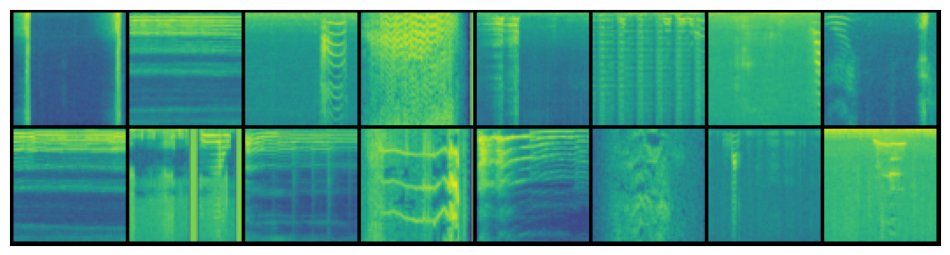

In [14]:
show_batch(train_dl)

In [15]:
def get_default_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')

def to_device(data, device):
    if isinstance(data, (list, tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader():
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        return len(self.dl)

In [20]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

class ImageClassificationBase(nn.Module):
    def training_step(self, batch):
        images, labels = batch
        out = self(images)
        loss = F.cross_entropy(out, labels)
        return loss

    def validation_step(self, batch):
        images, labels = batch
        out = self(images)
        loss = F.cross_entropy(out, labels)
        acc = accuracy(out, labels)
        return {'val_loss': loss.detach(), 'val_acc': acc}

    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]
        epoch_loss = torch.stack(batch_losses).mean()
        batch_accs = [x['val_acc'] for x in outputs]
        epoch_acc = torch.stack(batch_accs).mean()
        return {'val_loss': epoch_loss.item(), 'val_acc': epoch_acc.item()}

    def epoch_end(self, epoch, result):
        print("Epoch [{}], last_lr: {:.5f}, train_loss: {:.4f}, val_loss: {:.4f}, val_acc: {:.4f}".format(
            epoch, result['lrs'][-1], result['train_loss'], result['val_loss'], result['val_acc']
        ))

    def accuracy(outputs, labels):
        _ ,  preds = torch.max(outputs, dim=1)
        return torch.tensor(torch.sum(preds == labels).item() / len(preds))

In [21]:
device = get_default_device()
device

device(type='cpu')

In [22]:
train_dl = DeviceDataLoader(train_dl, device)
valid_dl = DeviceDataLoader(valid_dl, device)

In [24]:
def conv_block(in_channels, out_channels, pool=False):
    layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)]
    
    if pool: layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

In [25]:
class ResNet9(ImageClassificationBase):
    def __init__(self, in_channels, num_classes):
        super().__init__()

        self.conv1 = conv_block(in_channels, 64)
        self.conv2 = conv_block(64, 128, pool=True)
        self.res1 = nn.Sequential(conv_block(128, 128), conv_block(128, 128))
        self.conv3 = conv_block(128, 256, pool=True)
        self.conv4 = conv_block(256, 512, pool=True)
        self.res2 = nn.Sequential(conv_block(512, 512), conv_block(512, 512))
        self.classifier = nn.Sequential(
            nn.AdaptiveMaxPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, xb):
        out = self.conv1(xb)
        out = self.conv2(out)
        out = self.res1(out) + out
        out = self.conv3(out)
        out = self.conv4(out)
        out = self.res2(out) + out
        out = self.classifier(out)
        return out

In [26]:
no_of_classes = len(train.classes)
no_of_classes

2

In [28]:
model = to_device(ResNet9(3, no_of_classes), device)
model

ResNet9(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (res1): Sequential(
    (0): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_ru

In [29]:
@torch.no_grad()
def evaluate(model, val_loader):
    model.eval()
    outputs = [model.validation_step(batch) for batch in val_loader]
    return model.validation_epoch_end(outputs)

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def fit_one_cycle(epochs, max_lr, model, train_loader, val_loader,
                  weight_decay=0, grad_clip=None, opt_func=torch.optim.SGD):
    torch.cuda.empty_cache()
    history = []

    optimizer = opt_func(model.parameters(), max_lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr, epochs=epochs, steps_per_epoch=len(train_loader)
    )

    for epoch in range(epochs):
        model.train()
        train_losses = []
        lrs = []
        for batch in train_loader:
            loss = model.training_step(batch)
            train_losses.append(loss.detach())
            loss.backward()

            if grad_clip:
                nn.utils.clip_grad_value_(model.parameters(), grad_clip)

            optimizer.step()
            optimizer.zero_grad()

            lrs.append(get_lr(optimizer))
            sched.step()

        result = evaluate(model, val_loader)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        result['lrs'] = lrs
        model.epoch_end(epoch, result)
        history.append(result)
    return history

In [30]:
history = [evaluate(model, valid_dl)]
history

[{'val_loss': 0.6964668035507202, 'val_acc': 0.28437501192092896}]

In [31]:
epochs = 15
max_lr = 0.01
grad_clip = 0.1
weight_decay = 0.0004
opt_func = torch.optim.Adam

In [32]:
%%time
history += fit_one_cycle(
    epochs, max_lr, model, train_dl, valid_dl,
    grad_clip=grad_clip, weight_decay=weight_decay,
    opt_func=opt_func
)

Epoch [0], last_lr: 0.00137, train_loss: 1.2479, val_loss: 0.8383, val_acc: 0.2844
Epoch [1], last_lr: 0.00420, train_loss: 0.7161, val_loss: 0.5699, val_acc: 0.7312
Epoch [2], last_lr: 0.00751, train_loss: 0.4824, val_loss: 0.5769, val_acc: 0.8438
Epoch [3], last_lr: 0.00970, train_loss: 1.2417, val_loss: 0.6369, val_acc: 0.8125
Epoch [4], last_lr: 0.00994, train_loss: 1.5724, val_loss: 0.4837, val_acc: 0.8250
Epoch [5], last_lr: 0.00950, train_loss: 0.6544, val_loss: 1.0270, val_acc: 0.7594
Epoch [6], last_lr: 0.00867, train_loss: 0.4903, val_loss: 0.3117, val_acc: 0.9375
Epoch [7], last_lr: 0.00750, train_loss: 1.2391, val_loss: 0.8376, val_acc: 0.8750
Epoch [8], last_lr: 0.00611, train_loss: 0.5502, val_loss: 0.8823, val_acc: 0.7750
Epoch [9], last_lr: 0.00463, train_loss: 0.6492, val_loss: 0.1242, val_acc: 0.9531
Epoch [10], last_lr: 0.00317, train_loss: 0.3495, val_loss: 0.1083, val_acc: 0.9531
Epoch [11], last_lr: 0.00188, train_loss: 0.2937, val_loss: 0.2070, val_acc: 0.9531
Ep

In [33]:
def plot_accuracies(history):
    accuracies = [x['val_acc'] for x in history]
    plt.plot(accuracies, '-x')
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title('Accuracy vs Num of epochs')
    plt.show()

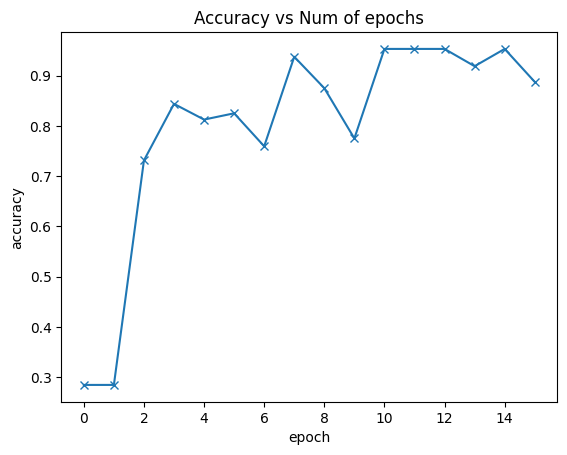

In [34]:
plot_accuracies(history)

In [35]:
def plot_losses(history):
    train_losses = [x.get('train_loss') for x in history]
    val_losses = [x['val_loss'] for x in history]
    plt.plot(train_losses, '-bx')
    plt.plot(val_losses, '-rx')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(['Training', 'Validation'])
    plt.title('Loss vs Num of epochs')
    plt.show()

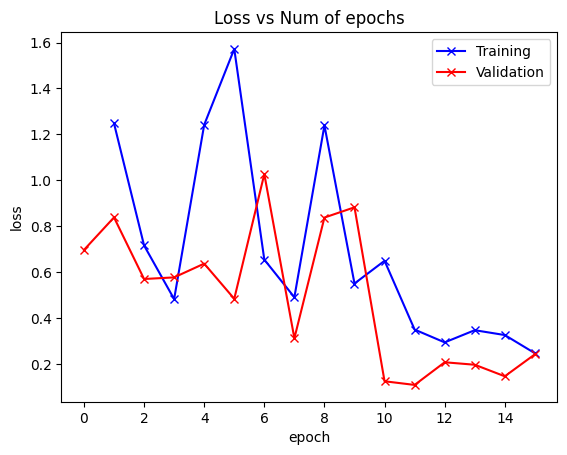

In [36]:
plot_losses(history)

In [38]:
no_of_classes = len(train.classes)
torch.save(model.state_dict(), 'fit_model.pt')

model_load = to_device(ResNet9(3, no_of_classes), device)
model_load.load_state_dict(torch.load('fit_model.pt', map_location=device, weights_only=True))

<All keys matched successfully>

In [39]:
model_load.eval()

ResNet9(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (res1): Sequential(
    (0): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_ru

In [40]:
test_transform = tt.Compose([
    tt.Resize((64, 64)),
    tt.ToTensor()
])

test = ImageFolder(test_spec_dir, transform=test_transform)

def predict_image(img, model):
    ximg = to_device(img.unsqueeze(0), device)
    with torch.no_grad():
        yimg = model(ximg)
    prob, preds = torch.max(yimg, dim=1)
    return test.classes[preds[0].item()]

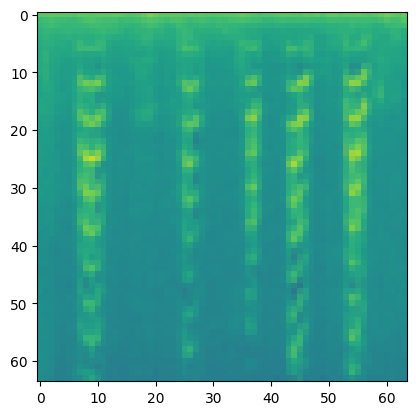

Actual: 0 (cat)
Predicted: cat


In [41]:
img, label = test[5]
plt.imshow(img.permute(1, 2, 0))
plt.show()
print("Actual:", label, f"({test.classes[label]})")
print("Predicted:", predict_image(img, model_load))

In [42]:
test.classes[label]

'cat'